# Analyse des séries temporelles et prévision — MeloWave (Mission 2)
**Auteur :** Lucas PIANEZZI  
**Rôle :** Data Analyst  
**Destinataire :** Camille Roussel (Directrice des études musicales)  
**Mission :** Modélisation de la présence des genres dans le Top 200, analyse tendancielle et prévision à 6 mois (Prophet).

## Sommaire
1. Construction et exploration de la série temporelle
   - 1.1. Choix du périmètre d'analyse
   - 1.2. Chargement, filtrage et préparation de la série chronologique
   - 1.3. Diagnostic des jours à zéro : Trou de collecte vs Vrai zéro
   - 1.4. Analyse de la tendance et de la saisonnalité (Moyenne mobile)
2. Modélisation et évaluation prédictive (Prophet)
   - 2.1. Évaluation de la performance du modèle
   - 2.2. Prévision finale à 6 mois et analyse des composantes
3. Analyse de la cadence de production (Rythme de sortie)
4. Synthèse et recommandations stratégiques

---

## 1. Construction et exploration de la série temporelle

### 1.1. Choix du périmètre d'analyse
Pour mener à bien cette étude prédictive, nous ciblons le genre Pop sur le marché Global. Ce périmètre offre une volumétrie d'écoute et une stabilité de présence dans les classements (Top 200) idéales pour tester la robustesse des modèles de prévision en s'affranchissant des variations imprévisibles propres aux genres niche.

In [1]:
# Importation des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration graphique
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Paramètres de filtrage modifiables
GENRE_CIBLE = "pop"       
MARCHE_CIBLE = "Global"

### 1.2. Chargement, filtrage et préparation de la série chronologique
Une absence de données non traitée fausse le calcul des saisonnalités et des moyennes mobiles.
La démarche est que nous avons reconstruit une grille de dates continue du premier au dernier jour de la période, en comblant les jours vacants, puis en passant les trous de collecte en valeur manquante (voir 1.3).

In [2]:
# Chargement optimisé des colonnes utiles du gros fichier
colonnes_utiles = ['country', 'date', 'genre', 'uri']
df_charts = pd.read_csv("chart_tracks_genre_2017_2020.csv", usecols=colonnes_utiles)

# Filtrage sur le genre et le marché
df_filtered = df_charts[
    (df_charts['genre'].str.lower() == GENRE_CIBLE.lower()) & 
    (df_charts['country'].str.lower() == MARCHE_CIBLE.lower())
].copy()

# Conversion de la date et construction de la série quotidienne (comptage des morceaux uniques)
df_filtered['date'] = pd.to_datetime(df_filtered['date'], format='%d/%m/%Y')
ts_genre = df_filtered.groupby('date')['uri'].nunique().reset_index(name='nb_tracks')

# Réindexation sur une grille complète de dates
date_range = pd.date_range(start=ts_genre['date'].min(), end=ts_genre['date'].max(), freq='D')
grid_df = pd.DataFrame({'date': date_range})

ts_full = pd.merge(grid_df, ts_genre, on='date', how='left').fillna({'nb_tracks': 0})
ts_full.set_index('date', inplace=True)

print(f"Série temporelle construite du {ts_full.index.min().strftime('%Y-%m-%d')} au {ts_full.index.max().strftime('%Y-%m-%d')}")
ts_full.head()

Série temporelle construite du 2017-01-01 au 2020-11-05


,nb_tracks
date,
2017-01-01,89.0
2017-01-02,87.0
2017-01-03,86.0
2017-01-04,86.0
2017-01-05,86.0


 La construction de cette série quotidienne et la réindexation garantissent l'intégrité de notre historique. Chaque jour de la période (du 1er janvier 2017 au 5 novembre 2020) possède une valeur, ce qui évitera tout biais d'analyse ou de fausse saisonnalité liée à des trous de collecte.

### 1.3. Diagnostic des jours à zéro : Trou de collecte vs Vrai zéro
Lorsque l'on étudie la présence quotidienne d'un genre dans le Top 200, certains jours peuvent afficher un total de zéro morceau. Il est primordial de distinguer deux réalités :
* **Le trou de collecte :** Le classement entier est absent ce jour-là.
* **Le vrai zéro :** Le marché fonctionne normalement, mais aucun morceau du genre Pop n'est présent dans le Top 200 ce jour-là.

Pour ce faire, nous comparons les zéros de notre série genre avec le volume total d'entrées du marché global.

In [3]:
# Série totale du marché (tous genres confondus), sur la même grille de dates
df_marche = df_charts[df_charts['country'].str.lower() == MARCHE_CIBLE.lower()].copy()
df_marche['date'] = pd.to_datetime(df_marche['date'], format='%d/%m/%Y')
total_marche = (df_marche.groupby('date')['uri'].nunique()
                .reindex(ts_full.index, fill_value=0))

# Jours à zéro du genre : trou de collecte (marché vide) ou vrai zéro (marché actif)
jours_zero = ts_full.index[ts_full['nb_tracks'] == 0]
trous_collecte = [d for d in jours_zero if total_marche[d] == 0]
vrais_zeros = [d for d in jours_zero if total_marche[d] > 0]

print(f"Jours à 0 pour le genre '{GENRE_CIBLE}' : {len(jours_zero)}")
print(f"Trous de collecte (marché vide) : {len(trous_collecte)} -> {[d.strftime('%d/%m/%Y') for d in trous_collecte]}")
print(f"Vrais zéros (marché actif)      : {len(vrais_zeros)}")

# Un trou de collecte n'est pas une absence du genre : on le passe en valeur manquante
ts_full.loc[trous_collecte, 'nb_tracks'] = np.nan

Jours à 0 pour le genre 'pop' : 5
Trous de collecte (marché vide) : 4 -> ['23/02/2017', '30/05/2017', '31/05/2017', '02/06/2017']
Vrais zéros (marché actif)      : 1


In [4]:
# Vérification du vrai zéro
jour = vrais_zeros[0]
print(f"Date : {jour:%d/%m/%Y}")
display(df_marche[df_marche['date'] == jour]['genre'].value_counts(dropna=False).head(10))

ts_full.loc[vrais_zeros, 'nb_tracks'] = np.nan

Date : 09/06/2018


genre
NaN    200
Name: count, dtype: int64

Sur la période, 5 jours sont à zéro pour la Pop. La comparaison avec la série totale du marché Global montre qu’aucun n’est un vrai zéro. Les 23/02/2017, 30/05/2017, 31/05/2017 et 02/06/2017, le classement entier est absent. Le 09/06/2018, il compte bien 200 lignes, mais sans genre renseigné et avec un seul titre distinct : la collecte a échoué. Ces 5 jours sont des trous de collecte, passés en valeur manquante pour ne pas fausser la tendance ni la saisonnalité. La Pop n’a donc jamais réellement disparu du Top 200 mondial.

### 1.4. Analyse de la tendance et de la saisonnalité (Moyenne mobile)
L'observation de la série brute quotidienne révèle un bruit important. L'ajout d'une moyenne mobile lissée sur 30 jours nous permet de détacher la tendance de fond des fluctuations à court terme, nous offrant une vision claire de la dynamique du genre.

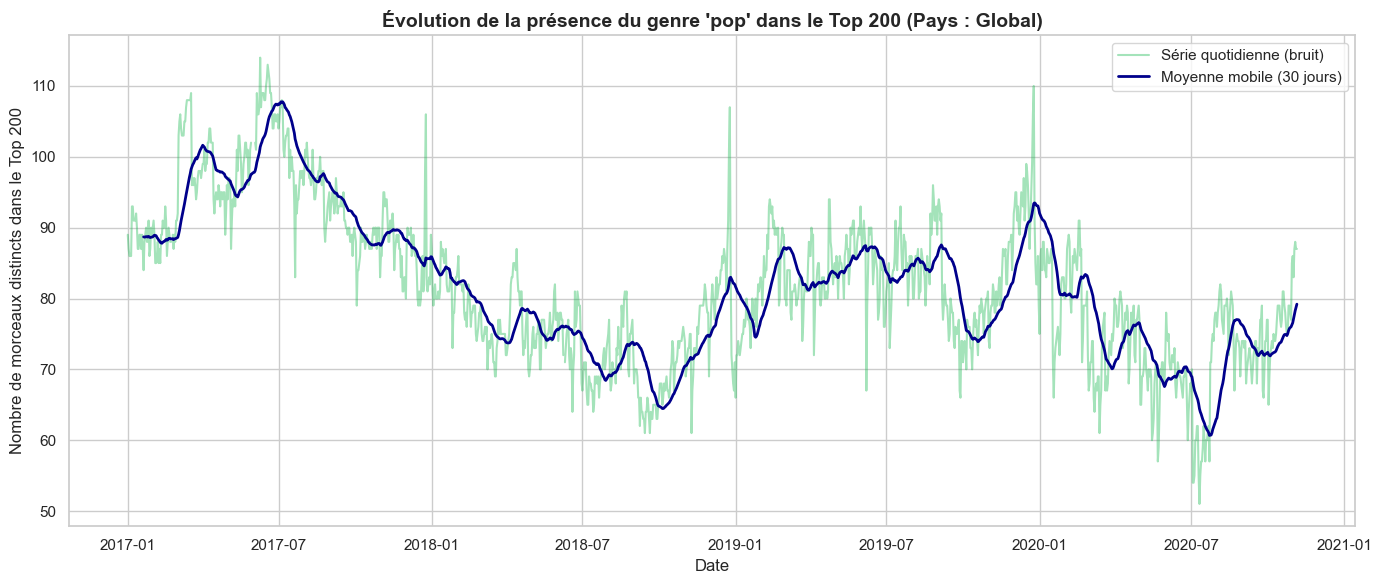

In [5]:
# Visualisation de la série quotidienne et de la moyenne mobile sur 30 jours
ts_full['rolling_mean_30'] = ts_full['nb_tracks'].rolling(window=30, min_periods=20).mean()

plt.figure(figsize=(14, 6))
plt.plot(ts_full.index, ts_full['nb_tracks'], label='Série quotidienne (bruit)', color='#1DB954', alpha=0.4)
plt.plot(ts_full.index, ts_full['rolling_mean_30'], label='Moyenne mobile (30 jours)', color='darkblue', linewidth=2)

plt.title(f"Évolution de la présence du genre '{GENRE_CIBLE}' dans le Top 200 (Pays : {MARCHE_CIBLE})", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Nombre de morceaux distincts dans le Top 200")
plt.legend()
plt.tight_layout()
plt.show()

> * **Bruit vs Tendance :** La série brute (en vert clair) montre de fortes variations quotidiennes instables, inhérentes à la rotation rapide des morceaux dans les charts (entrées massives de nouveautés, effets weekend).
> * **Dynamique de fond :** La moyenne mobile à 30 jours (en bleu foncé) lisse ces fluctuations à court terme et met en évidence la tendance tendancielle de fond. La moyenne mobile oscille entre 60 et 110 titres, avec un pic mi-2017, un creux fin 2018 et un recul progressif depuis 2020.

## 2. Modélisation et évaluation prédictive (Prophet)

Dans cette partie, nous allons mettre en place un modèle de prévision par séries temporelles avec Prophet. Pour cela nous suivons un protocole d'évaluation en deux temps :
1. **Backtesting sur les 90 derniers jours :** Nous masquons la fin de l'historique pour évaluer la capacité du modèle à anticiper le réel.
2. **Prévision finale à 6 mois :** Après validation des performances, nous ré-entraînons le modèle sur l'intégralité des données pour projeter la tendance future.

In [6]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Préparation des données au format attendu par Prophet ('ds' datestamp pour la date, 'y' pour la métrique)
df_prophet = ts_full.reset_index()[['date', 'nb_tracks']].rename(
    columns={'date': 'ds', 'nb_tracks': 'y'}
)

# Protocole d'évaluation : séparation entraînement / test (mise de côté des 90 derniers jours)
test_days = 90
df_train = df_prophet.iloc[:-test_days].copy()
df_test = df_prophet.iloc[-test_days:].copy()

print(f"Période d'entraînement : du {df_train['ds'].min().strftime('%Y-%m-%d')} au {df_train['ds'].max().strftime('%Y-%m-%d')}")
print(f"Période de test (évaluation) : du {df_test['ds'].min().strftime('%Y-%m-%d')} au {df_test['ds'].max().strftime('%Y-%m-%d')}")

# Configuration et entraînement du modèle Prophet
# On active les saisonnalités annuelle et hebdomadaire, et on désactive la saisonnalité quotidienne.
model_eval = Prophet(
    yearly_seasonality=True, 
    weekly_seasonality=True, 
    daily_seasonality=False
)
model_eval.fit(df_train)

# Prédiction sur la période de test
future_test = model_eval.make_future_dataframe(periods=test_days, include_history=False)
forecast_test = model_eval.predict(future_test)

11:44:23 - cmdstanpy - INFO - Chain [1] start processing


Période d'entraînement : du 2017-01-01 au 2020-08-07
Période de test (évaluation) : du 2020-08-08 au 2020-11-05


11:44:24 - cmdstanpy - INFO - Chain [1] done processing


### 2.1. Évaluation de la performance du modèle
Pour mesurer l'écart entre la réalité et nos prévisions sur la période de test (les 90 derniers jours), nous utilisons trois métriques :
* **MAE (Mean Absolute Error) :** L'erreur absolue moyenne en nombre de morceaux.
* **RMSE (Root Mean Squared Error) :** La racine de l'erreur quadratique moyenne (pénalise plus fortement les grosses erreurs).
* **MAPE (Mean Absolute Percentage Error) :** L'erreur (%).

Performances du modèle sur les 90 jours de test
MAE  : 17.77 morceaux
RMSE : 19.03 morceaux
MAPE : 23.33%


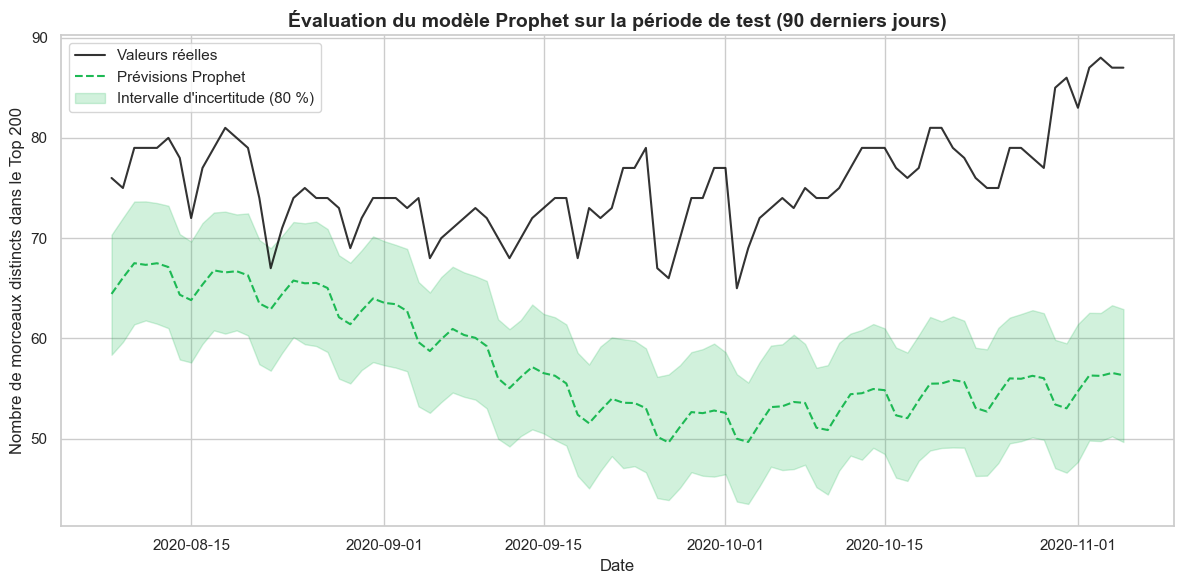

In [7]:
# Extraction des valeurs réelles et prédites
y_true = df_test['y'].values
y_pred = forecast_test['yhat'].values

# Calcul des métriques
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("Performances du modèle sur les 90 jours de test")
print(f"MAE  : {mae:.2f} morceaux")
print(f"RMSE : {rmse:.2f} morceaux")
print(f"MAPE : {mape:.2f}%")

# Visualisation graphique de l'évaluation
plt.figure(figsize=(12, 6))
plt.plot(df_test['ds'], y_true, label='Valeurs réelles', color='black', alpha=0.8)
plt.plot(df_test['ds'], y_pred, label='Prévisions Prophet', color='#1DB954', linestyle='--')
plt.fill_between(
    df_test['ds'], 
    forecast_test['yhat_lower'], 
    forecast_test['yhat_upper'], 
    color='#1DB954', alpha=0.2, 
    label='Intervalle d\'incertitude (80 %)'
)
plt.title("Évaluation du modèle Prophet sur la période de test (90 derniers jours)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Nombre de morceaux distincts dans le Top 200")
plt.legend()
plt.tight_layout()
plt.show()

Sur les 90 jours de test, le modèle se trompe en moyenne de 17.77 titres Pop par jour (MAE), soit environ  23.33 % d'écart (MAPE). Le RMSE : 19.03 est proche de la MAE : il y a peu de grosses erreurs isolées, l'écart est régulier. Sur le graphique, le modèle sous-estime la réalité sur l'essentiel de la période. La Pop compte toujours plusieurs dizaines de titres par jour, jamais proche de 0 : la MAPE reste donc fiable ici.

### 2.2. Prévision finale à 6 mois et analyse des composantes
Le backtesting montre une erreur moyenne de 18 titres par jour et une sous-estimation systématique : la prévision sera donc lue comme une tendance, pas comme un niveau exact. Nous ré-entraînons le modèle sur l’ensemble des données pour produire la prévision à 6 mois avec ses intervalles de confiance.

11:44:24 - cmdstanpy - INFO - Chain [1] start processing
11:44:24 - cmdstanpy - INFO - Chain [1] done processing


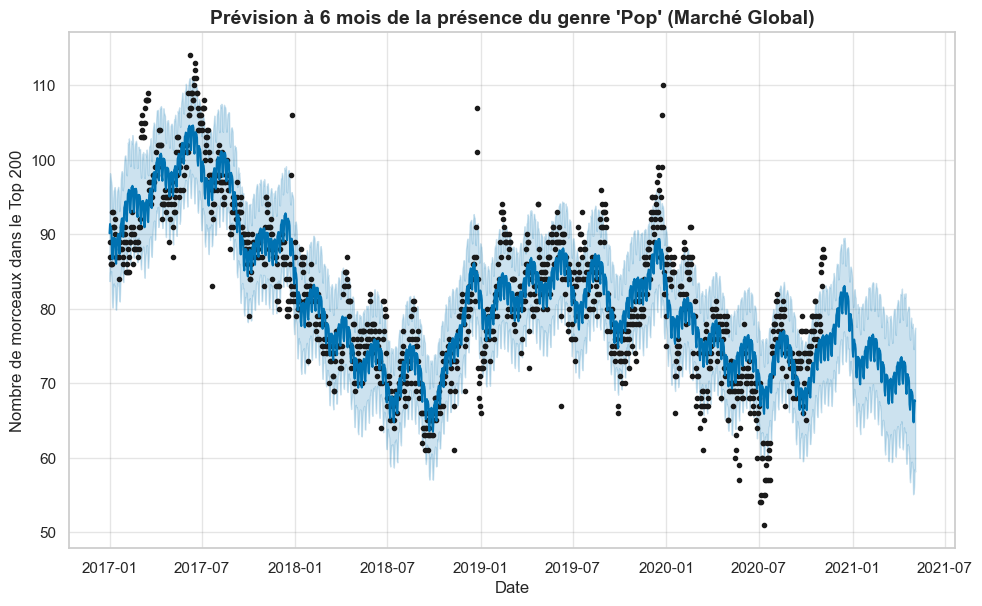

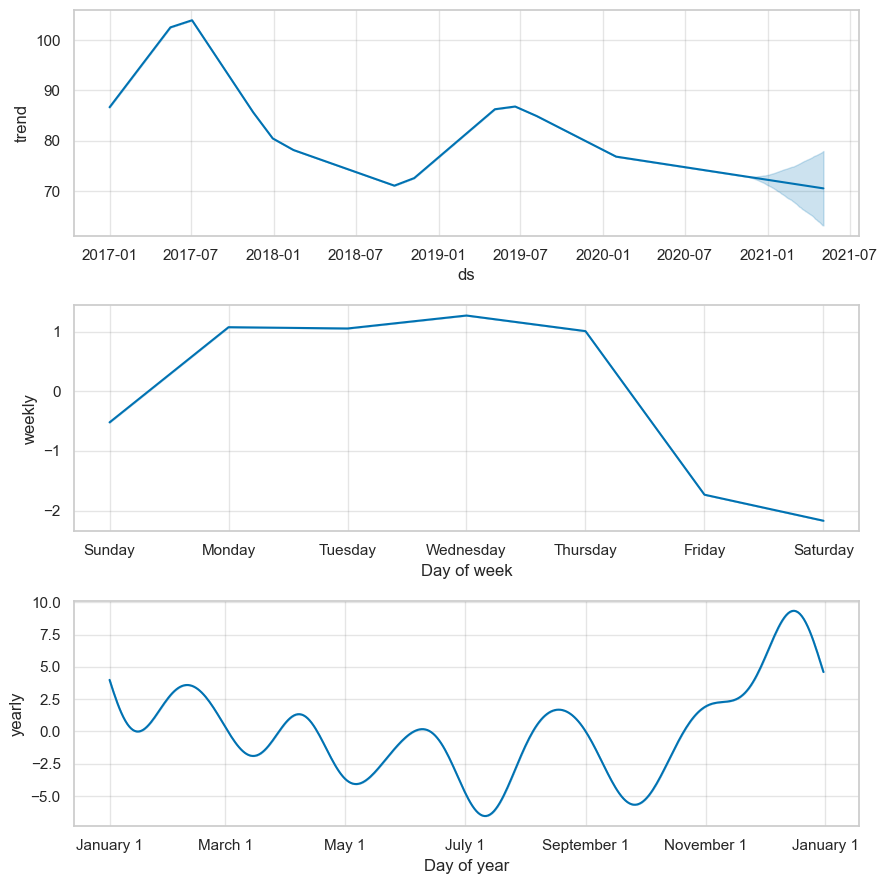

In [8]:
# Ré-entraînement sur l'intégralité du dataset connu
model_final = Prophet(
    yearly_seasonality=True, 
    weekly_seasonality=True, 
    daily_seasonality=False
)
model_final.fit(df_prophet)

# Génération du futur à 6 mois (180 jours)
future_6months = model_final.make_future_dataframe(periods=180)
forecast_6months = model_final.predict(future_6months)

# Graphique de la prévision globale
fig1 = model_final.plot(forecast_6months)
plt.title("Prévision à 6 mois de la présence du genre 'Pop' (Marché Global)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Nombre de morceaux dans le Top 200")
plt.show()

# Affichage des composantes (Tendance, Saisonnalité hebdomadaire, Saisonnalité annuelle)
fig2 = model_final.plot_components(forecast_6months)
plt.show()

>**Interprétation des composantes pour les labels :**
> * **Tendance :** la Pop évolue par vagues (pics à 104 titres mi-2017 et 87 mi-2019) mais recule globalement, de 87 titres en 2017 à environ 73 fin 2020. Prophet prolonge cette baisse jusqu’à environ 70 titres à mi-2021.
> * **Hebdomadaire :**  la Pop est légèrement plus présente du lundi au jeudi et recule le vendredi et le samedi, quand les nouveautés de tous genres entrent dans le classement. L’effet est faible (environ 3 titres d’écart).
> * **Annuelle :** effet le plus fort. Pic en décembre (+9 titres, chansons de Noël), creux début juillet (−6,5) et début octobre (−5,5), quand les tubes d’été d’autres genres dominent.
> 
>**Limites :** Cette prévision repose sur l'hypothèse de la continuité des motifs passés. La fiabilité de la prévision diminue à mesure que l'horizon s'éloigne (incertitude accrue au-delà de 3 mois).

## 3. Analyse de la cadence de production (Rythme de sortie)

Les labels nous demandent d'analyser la cadence mensuelle de production et de sortie des morceaux du genre Pop. 

Ici l'objectif est d'étudier le rythme de création et voir si l'on peut anticiper la dynamique de production à l'aide d'un modèle Prophet mensuel.

In [9]:
# Chargement du fichier des dates de sortie
df_releases = pd.read_csv("release_dates_genre_2017_2020.csv")

# Filtrage sur le genre cible (Pop) 
df_releases_pop = df_releases[df_releases['Genre_new'].str.lower() == GENRE_CIBLE.lower()].copy()

# Conversion de la date de sortie 
df_releases_pop['Release_date'] = pd.to_datetime(df_releases_pop['Release_date'])

# Agrégation mensuelle : comptage du nombre de sorties par mois

#Extraction du mois et année de chaque date
df_releases_pop['month_year'] = df_releases_pop['Release_date'].dt.to_period('M')

#Regroupement des morceaux par mois et comptage d'identifiants uniques pour chaque mois.
ts_monthly = df_releases_pop.groupby('month_year')['Uri'].count().reset_index(name='nb_releases')

#Préparation tableau compatibilité Prophet (ds et y)
ts_monthly['ds'] = ts_monthly['month_year'].dt.to_timestamp()
ts_monthly = ts_monthly.sort_values('ds')[['ds', 'nb_releases']].rename(columns={'nb_releases': 'y'})

print(f"Série mensuelle construite : {len(ts_monthly)} mois analysés.")
ts_monthly.head()

Série mensuelle construite : 46 mois analysés.


,ds,y
0,2017-01-01,190
1,2017-02-01,252
2,2017-03-01,332
3,2017-04-01,291
4,2017-05-01,353


11:44:24 - cmdstanpy - INFO - Chain [1] start processing
11:44:25 - cmdstanpy - INFO - Chain [1] done processing


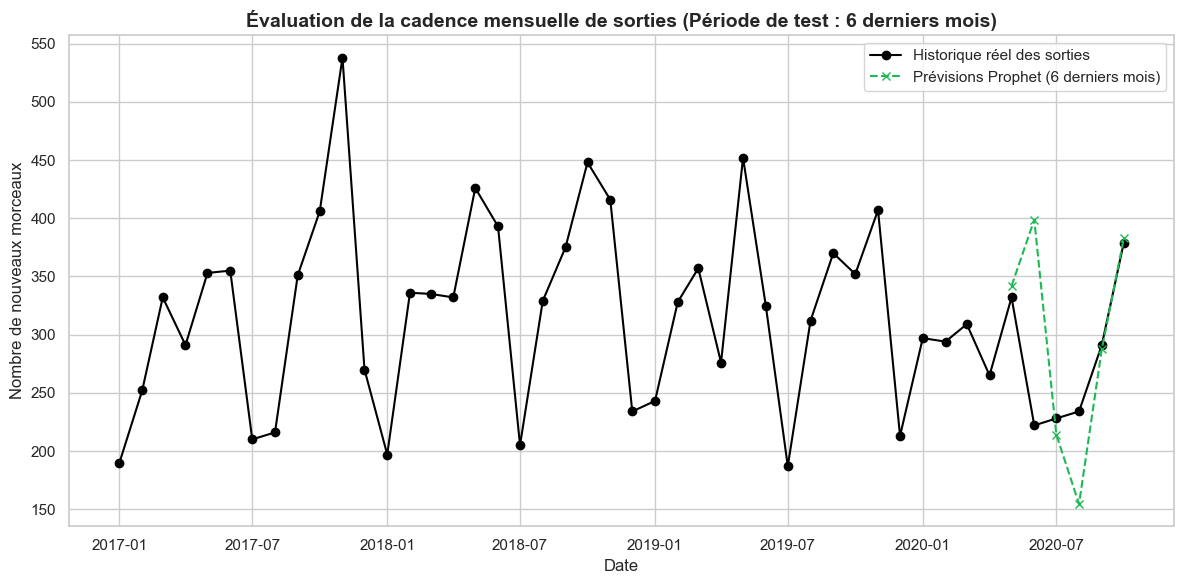

In [10]:
# Protocole d'évaluation : test sur les 6 derniers mois
test_months = 6
df_train_m = ts_monthly.iloc[:-test_months].copy()
df_test_m = ts_monthly.iloc[-test_months:].copy()

# Entraînement du modèle Prophet sur les données mensuelles
model_monthly = Prophet(
    yearly_seasonality=True, 
    weekly_seasonality=False, 
    daily_seasonality=False
)
model_monthly.fit(df_train_m)

# Prédiction sur les 6 derniers mois
future_monthly = model_monthly.make_future_dataframe(periods=test_months, freq='MS', include_history=False)
forecast_monthly = model_monthly.predict(future_monthly)

# Visualisation Réel vs Prévu (Cadence mensuelle)
plt.figure(figsize=(12, 6))
plt.plot(ts_monthly['ds'], ts_monthly['y'], label='Historique réel des sorties', color='black', marker='o')
plt.plot(df_test_m['ds'], forecast_monthly['yhat'].values, label='Prévisions Prophet (6 derniers mois)', color='#1DB954', linestyle='--', marker='x')
plt.title("Évaluation de la cadence mensuelle de sorties (Période de test : 6 derniers mois)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Nombre de nouveaux morceaux")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
y_true_m = df_test_m['y'].values
y_pred_m = forecast_monthly['yhat'].values

mae_m = mean_absolute_error(y_true_m, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_true_m, y_pred_m))
mape_m = np.mean(np.abs((y_true_m - y_pred_m) / y_true_m)) * 100

print("Performances sur les 6 derniers mois")
print(f"MAE  : {mae_m:.1f} sorties par mois")
print(f"RMSE : {rmse_m:.1f} sorties par mois")
print(f"MAPE : {mape_m:.1f} %")
display(pd.DataFrame({'Mois': df_test_m['ds'].dt.strftime('%m/%Y'),
                      'Réel': y_true_m, 'Prévu': y_pred_m.round(0)}))

Performances sur les 6 derniers mois
MAE  : 47.9 sorties par mois
RMSE : 79.5 sorties par mois
MAPE : 20.8 %


,Mois,Réel,Prévu
40,05/2020,332,342.0
41,06/2020,222,399.0
42,07/2020,228,214.0
43,08/2020,234,155.0
44,09/2020,291,287.0
45,10/2020,379,383.0


* Évaluation : sur les 6 derniers mois, le modèle se trompe en moyenne de 48 sorties par mois (MAPE 20,8 %). Il est précis pour mai, juillet, septembre et octobre (moins de 15 sorties d’écart), mais rate juin (+177) et août (−79). Le RMSE (79,5), bien supérieur à la MAE, confirme que l’erreur vient de ces deux mois : Prophet reproduit le rythme annuel moyen, pas les variations propres à 2020.

* Biais de fin de période : le fichier ne recense que les morceaux ayant atteint les classements, et la collecte s’arrête le 5 novembre 2020. Un morceau sorti fin 2020 a donc eu moins de temps pour entrer dans le Top 200 qu’un morceau sorti en 2017. Ce biais n’est pas encore visible dans la série, qui s’arrête en octobre, mais il fragilise toute prévision future : les sorties les plus récentes seront sous-comptées.

### 4. Synthèse et recommandations stratégiques

Nous pouvons synthétiser les grands points à retenir de notre analyse prédictive sur la Pop mondiale (2017-2020) :

1. **Une Pop installée mais en recul :**
   * la Pop occupe toujours plusieurs dizaines de places du Top 200 mondial, mais sa tendance baisse, de 87 titres début 2017 à environ 73 fin 2020.
2. **Un calendrier annuel marqué :**
   * la Pop culmine en décembre (+9 titres, chansons de Noël) et recule début juillet et début octobre (environ −6). Ce sont les périodes à privilégier ou à éviter pour une sortie.
3. **Un effet semaine faible :**
   * la Pop recule légèrement le vendredi et le samedi (environ −2 titres), quand les nouveautés de tous genres entrent dans le classement.
4. **Une prévision à lire comme une tendance :**
   * testé sur 90 jours, le modèle se trompe en moyenne de 18 titres par jour (23 %) et sous-estime systématiquement la Pop. La prévision à 6 mois indique la direction et les périodes favorables, mais son niveau est probablement trop bas, et l'incertitude grandit avec le temps.
5. **Un rythme de sortie peu prévisible :**
   * la prévision mensuelle se trompe de 48 sorties par mois en moyenne (20,8 %). Elle est aussi fragilisée par le biais de fin de période : les titres sortis fin 2020 n'ont pas eu le temps d'entrer dans les classements.